# Évaluation Complète du Modèle Attention Deep Sets (`../models/detection_error_src.pt`)

Ce notebook charge le checkpoint sauvegardé (`../models/detection_error_src.pt`) pour l'architecture **`AttentionDeepSetsDiagnostic`** (Mean Pooling + Attention Pooling par cible) et évalue les performances sur le dataset (`D:/S5/Projet_d_expertise/projet/data/processed/detection_error_src.csv`) :
1. **Chargement** du modèle `AttentionDeepSetsDiagnostic`, du `StandardScaler`, des colonnes et du seuil $C$.
2. **Métriques multi-label globales** (`F1-Micro`, `F1-Macro`, `Precision_Micro`, `Recall_Micro`, `Hamming Loss`, `Exact Match`) selon le seuil $C$.
3. **Courbe de sensibilité au seuil $C$** (de `0.10` à `0.80`) pour recalibrer le seuil optimal (notamment si `pos_weight` a été utilisé à l'entraînement).
4. **Performance détaillée par entité** (Précision, Rappel, F1-Score, Support sur les 21 cibles : machines, opérateurs, capteurs, contrôleurs).
5. **Test d'inférence sans réentraînement** sur d'autres regroupements (`Operation_Type`, `Cable_ID`).

In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score, hamming_loss, accuracy_score
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Appareil utilisé :', device)

Appareil utilisé : cpu


## 1. Définition de `AttentionDeepSetsDiagnostic` et chargement du checkpoint unique

In [26]:
class AttentionDeepSetsDiagnostic(nn.Module):
    def __init__(self, in_features: int, hidden_dim: int = 128, num_targets: int = 21):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )
        self.attn_score = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, num_targets)
        )
        self.rho = nn.Sequential(
            nn.Linear(hidden_dim + hidden_dim * num_targets, hidden_dim * 2),
            nn.LayerNorm(hidden_dim * 2),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim * 2, num_targets)
        )
        self.num_targets = num_targets

    def forward(self, x_events: torch.Tensor, group_idx: torch.Tensor, num_groups: int) -> torch.Tensor:
        h = self.phi(x_events)
        dev = x_events.device
        dim = h.size(1)

        # 1. Mean Pooling global du groupe
        sum_pool = torch.zeros((num_groups, dim), device=dev, dtype=h.dtype)
        sum_pool.index_add_(0, group_idx, h)
        counts = torch.zeros((num_groups, 1), device=dev, dtype=h.dtype)
        counts.index_add_(0, group_idx, torch.ones((h.size(0), 1), device=dev, dtype=h.dtype))
        mean_pool = sum_pool / counts.clamp(min=1.0)

        # 2. Attention Pooling par cible
        scores = self.attn_score(h)
        max_scores = torch.full((num_groups, self.num_targets), -1e9, device=dev, dtype=h.dtype)
        max_scores.scatter_reduce_(
            0, group_idx.unsqueeze(1).expand(-1, self.num_targets), scores, reduce='amax', include_self=True
        )
        exp_scores = torch.exp(scores - max_scores[group_idx])
        denom = torch.zeros((num_groups, self.num_targets), device=dev, dtype=h.dtype)
        denom.index_add_(0, group_idx, exp_scores)
        attn_weights = exp_scores / denom[group_idx].clamp(min=1e-8)

        weighted_h = attn_weights.unsqueeze(-1) * h.unsqueeze(1)
        attn_pool = torch.zeros((num_groups, self.num_targets, dim), device=dev, dtype=h.dtype)
        attn_pool.index_add_(0, group_idx, weighted_h)
        attn_flat = attn_pool.reshape(num_groups, -1)

        # 3. Fusion et prédiction
        combined = torch.cat([mean_pool, attn_flat], dim=1)
        return self.rho(combined)

CHECKPOINT_PATH = '../models/detection_error_src.pt'

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(f'Checkpoint introuvable : {CHECKPOINT_PATH}')

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model = AttentionDeepSetsDiagnostic(
    in_features=checkpoint['in_features'],
    hidden_dim=checkpoint['hidden_dim'],
    num_targets=checkpoint['num_targets']
).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

scaler = checkpoint['scaler']
FEATURE_COLS = checkpoint['feature_cols']
ALL_ENTITIES = checkpoint['entities']
TARGET_COLS = [f'Target_Prob_{e}' for e in ALL_ENTITIES]
THRESHOLD = checkpoint.get('threshold', 0.30)

print(f'Checkpoint chargé depuis : {CHECKPOINT_PATH} | Seuil C par défaut : {THRESHOLD}')

Checkpoint chargé depuis : ../models/detection_error_src.pt | Seuil C par défaut : 0.3


## 2. Préparation des données et construction des groupes d'évaluation

In [27]:
DATA_PATH = 'D:/S5/Projet_d_expertise/projet/data/processed/detection_error_src.csv'
df = pd.read_csv(DATA_PATH)

NUM_COLS = [
    'Step_Order', 'Total_Cable_Steps', 'Num_Machine_Ops', 'Num_Manual_Ops',
    'Hours_Into_Shift',
    'Machine_Hours_Since_Maint', 'Machine_Vibration_mm_s', 'Machine_Temp_C', 'Machine_Cycle_Time_sec',
    'Operator_Exp_Months', 'Operator_Handling_Time_sec',
    'Sensor_Calibration_Drift', 'Sensor_Anomaly_Score', 'Sensor_Error_Flag',
    'Inspection_Duration_sec', 'Human_Error_Flag',
    'Step_Observed_Error', 'Confirmed_Physical_Defect'
]
CAT_COLS = ['Shift', 'Operation_Mode', 'Operation_Type', 'Machine_ID', 'Operator_ID', 'Sensor_ID', 'Inspector_ID', 'Control_Mode']

df_num = df[NUM_COLS].fillna(0.0).copy()
df_cat = pd.get_dummies(df[CAT_COLS].fillna('NONE'), dtype=np.float32)
X_raw = pd.concat([df_num, df_cat], axis=1)

for col in FEATURE_COLS:
    if col not in X_raw.columns:
        X_raw[col] = 0.0
X_raw = X_raw[FEATURE_COLS].astype(np.float32)

X_all = pd.DataFrame(
    scaler.transform(X_raw),
    index=X_raw.index,
    columns=FEATURE_COLS,
    dtype=np.float32
)
X_all['Batch_ID'] = df['Batch_ID'].values
X_all['Cable_ID'] = df['Cable_ID'].values
X_all['Operation_Type'] = df['Operation_Type'].values

batch_targets = df.groupby('Batch_ID', sort=True)[TARGET_COLS].first()
_, test_batches = train_test_split(batch_targets.index.tolist(), test_size=0.25, random_state=SEED)

def build_group_samples(df_feat: pd.DataFrame, group_col: str, targets_df: pd.DataFrame = None):
    samples = []
    for gid, grp in df_feat.groupby(group_col, sort=False):
        arr = grp[FEATURE_COLS].values.astype(np.float32)
        if len(arr) == 0:
            continue
        y_vec = targets_df.loc[gid].values.astype(np.float32) if (targets_df is not None and gid in targets_df.index) else None
        samples.append((gid, arr, y_vec))
    return samples

class EventSetDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        gid, feats, target = self.samples[idx]
        return gid, torch.tensor(feats, dtype=torch.float32), (torch.tensor(target, dtype=torch.float32) if target is not None else None)

def collate_variable_sets(batch):
    gids, feat_list, target_list = zip(*batch)
    group_ids = [torch.full((f.size(0),), i, dtype=torch.long) for i, f in enumerate(feat_list)]
    y_out = torch.stack(target_list, dim=0) if target_list[0] is not None else None
    return gids, torch.cat(feat_list, dim=0), torch.cat(group_ids, dim=0), len(feat_list), y_out

def predict_probabilities(samples_list):
    loader = DataLoader(EventSetDataset(samples_list), batch_size=32, shuffle=False, collate_fn=collate_variable_sets)
    all_gids, all_probs, all_targets = [], [], []
    with torch.no_grad():
        for gids, x_cat, g_idx, n_grp, y_batch in loader:
            x_cat, g_idx = x_cat.to(device), g_idx.to(device)
            probs = torch.sigmoid(model(x_cat, g_idx, n_grp)).cpu().numpy()
            all_gids.extend(gids)
            all_probs.append(probs)
            if y_batch is not None:
                all_targets.append(y_batch.numpy())
    probs_df = pd.DataFrame(np.vstack(all_probs), index=all_gids, columns=ALL_ENTITIES)
    targets_mat = np.vstack(all_targets) if all_targets else None
    return probs_df, targets_mat

test_samples = build_group_samples(X_all[X_all['Batch_ID'].isin(test_batches)], 'Batch_ID', batch_targets)
probs_test_df, y_test_mat = predict_probabilities(test_samples)
print('Échantillons de test évalués :', len(test_samples))

Échantillons de test évalués : 100


## 3. Métriques globales et courbe de calibration selon le seuil $C$

Meilleur seuil selon F1-Micro : {'Seuil_C': 0.8, 'F1_Micro': 0.6280193236714976, 'F1_Macro': 0.4460069250217034, 'Precision_Micro': 0.8024691358024691, 'Recall_Micro': 0.5158730158730159, 'Hamming_Loss': 0.03666666666666667, 'Exact_Match': 0.51}
Meilleur seuil selon F1-Macro : {'Seuil_C': 0.5, 'F1_Micro': 0.5912408759124088, 'F1_Macro': 0.49119126308066396, 'Precision_Micro': 0.5472972972972973, 'Recall_Micro': 0.6428571428571429, 'Hamming_Loss': 0.05333333333333334, 'Exact_Match': 0.42}


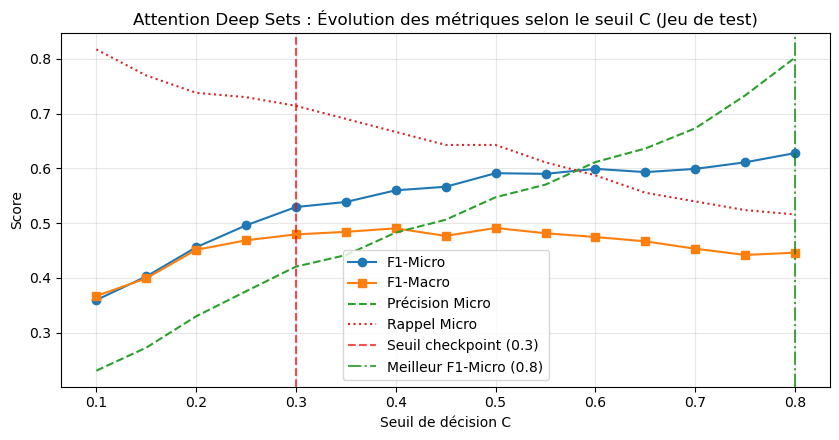

,Seuil_C,F1_Micro,F1_Macro,Precision_Micro,Recall_Micro,Hamming_Loss,Exact_Match
0,0.10,0.3595,0.3669,0.2304,0.8175,0.1748,0.08
1,0.15,0.4025,0.3991,0.2725,0.7698,0.1371,0.14
2,0.20,0.4559,0.4512,0.3298,0.7381,0.1057,0.23
3,0.25,0.4960,0.4686,0.3755,0.7302,0.0890,0.28
4,0.30,0.5294,0.4794,0.4206,0.7143,0.0762,0.34
5,0.35,0.5387,0.4841,0.4416,0.6905,0.0710,0.36
6,0.40,0.5600,0.4904,0.4828,0.6667,0.0629,0.37
7,0.45,0.5664,0.4767,0.5062,0.6429,0.0590,0.40
8,0.50,0.5912,0.4912,0.5473,0.6429,0.0533,0.42
9,0.55,0.5900,0.4815,0.5704,0.6111,0.0510,0.43


In [28]:
thresholds = np.round(np.arange(0.10, 0.85, 0.05), 2)
curve_rows = []
for th in thresholds:
    preds = (probs_test_df.values >= th).astype(int)
    curve_rows.append({
        'Seuil_C': th,
        'F1_Micro': f1_score(y_test_mat, preds, average='micro', zero_division=0),
        'F1_Macro': f1_score(y_test_mat, preds, average='macro', zero_division=0),
        'Precision_Micro': precision_score(y_test_mat, preds, average='micro', zero_division=0),
        'Recall_Micro': recall_score(y_test_mat, preds, average='micro', zero_division=0),
        'Hamming_Loss': hamming_loss(y_test_mat, preds),
        'Exact_Match': accuracy_score(y_test_mat, preds)
    })

curve_df = pd.DataFrame(curve_rows)
best_micro_row = curve_df.loc[curve_df['F1_Micro'].idxmax()]
best_macro_row = curve_df.loc[curve_df['F1_Macro'].idxmax()]
print('Meilleur seuil selon F1-Micro :', best_micro_row.to_dict())
print('Meilleur seuil selon F1-Macro :', best_macro_row.to_dict())

plt.figure(figsize=(8.5, 4.5))
plt.plot(curve_df['Seuil_C'], curve_df['F1_Micro'], marker='o', label='F1-Micro')
plt.plot(curve_df['Seuil_C'], curve_df['F1_Macro'], marker='s', label='F1-Macro')
plt.plot(curve_df['Seuil_C'], curve_df['Precision_Micro'], linestyle='--', label='Précision Micro')
plt.plot(curve_df['Seuil_C'], curve_df['Recall_Micro'], linestyle=':', label='Rappel Micro')
plt.axvline(THRESHOLD, color='red', linestyle='--', alpha=0.7, label=f'Seuil checkpoint ({THRESHOLD})')
plt.axvline(best_micro_row['Seuil_C'], color='green', linestyle='-.', alpha=0.7, label=f"Meilleur F1-Micro ({best_micro_row['Seuil_C']})")
plt.xlabel('Seuil de décision C')
plt.ylabel('Score')
plt.title('Attention Deep Sets : Évolution des métriques selon le seuil C (Jeu de test)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(curve_df.round(4))

## 4. Évaluation détaillée par entité (`21` cibles) et inférence sur d'autres regroupements

In [29]:
# Utilise le meilleur seuil F1-Micro (ou remplacez par THRESHOLD si vous souhaitez garder 0.30)
EVAL_THRESHOLD = float(best_micro_row['Seuil_C'])
preds_test_mat = (probs_test_df.values >= EVAL_THRESHOLD).astype(int)

entity_rows = []
for idx_e, ent in enumerate(ALL_ENTITIES):
    y_true_e = y_test_mat[:, idx_e]
    y_pred_e = preds_test_mat[:, idx_e]
    entity_rows.append({
        'Entite': ent,
        'Support_Positifs': int(y_true_e.sum()),
        'Predits_Positifs': int(y_pred_e.sum()),
        'Precision': round(precision_score(y_true_e, y_pred_e, zero_division=0), 4),
        'Rappel': round(recall_score(y_true_e, y_pred_e, zero_division=0), 4),
        'F1': round(f1_score(y_true_e, y_pred_e, zero_division=0), 4),
        'Prob_Moyenne': round(float(probs_test_df.iloc[:, idx_e].mean()), 4)
    })

entity_eval_df = pd.DataFrame(entity_rows)
print(f'=== Résumé au seuil optimal C = {EVAL_THRESHOLD} ===')
print(f'F1-Micro     : {f1_score(y_test_mat, preds_test_mat, average="micro", zero_division=0):.4f}')
print(f'F1-Macro     : {f1_score(y_test_mat, preds_test_mat, average="macro", zero_division=0):.4f}')
print(f'Hamming Loss : {hamming_loss(y_test_mat, preds_test_mat):.4f}')
display(entity_eval_df)

# Test sans réentraînement sur un autre regroupement (Operation_Type)
op_samples = build_group_samples(X_all, 'Operation_Type', targets_df=None)
op_probs_df, _ = predict_probabilities(op_samples)
print('\n=== Probabilités moyennes par Operation_Type (sans réentraînement) ===')
display(op_probs_df.round(3))

=== Résumé au seuil optimal C = 0.8 ===
F1-Micro     : 0.6280
F1-Macro     : 0.4460
Hamming Loss : 0.0367


,Entite,Support_Positifs,Predits_Positifs,Precision,Rappel,F1,Prob_Moyenne
0,MACH_01,13,12,0.7500,0.6923,0.7200,0.1780
1,MACH_02,16,13,0.9231,0.7500,0.8276,0.1843
2,MACH_03,9,5,1.0000,0.5556,0.7143,0.1132
3,MACH_04,11,7,1.0000,0.6364,0.7778,0.1505
4,MACH_05,12,12,0.8333,0.8333,0.8333,0.1625
5,OP_01,7,1,1.0000,0.1429,0.2500,0.1274
6,OP_02,3,5,0.2000,0.3333,0.2500,0.1409
7,OP_03,9,0,0.0000,0.0000,0.0000,0.1283
8,OP_04,7,2,1.0000,0.2857,0.4444,0.1197
9,OP_05,7,6,0.6667,0.5714,0.6154,0.1344



=== Probabilités moyennes par Operation_Type (sans réentraînement) ===


,MACH_01,MACH_02,MACH_03,MACH_04,MACH_05,OP_01,OP_02,OP_03,OP_04,OP_05,...,OP_07,OP_08,SENS_01,SENS_02,SENS_03,SENS_04,INSP_01,INSP_02,INSP_03,INSP_04
Denudage,0.018,0.039,0.006,0.006,0.161,0.006,0.062,0.006,0.024,0.092,...,0.013,0.017,0.031,0.087,0.089,0.248,0.000,0.001,0.000,0.004
Test_Continuite_Auto,0.007,0.010,0.039,0.061,0.184,0.003,0.004,0.005,0.028,0.014,...,0.004,0.024,0.010,0.013,0.085,0.170,0.001,0.000,0.001,0.002
Epissure_Manuelle,0.005,0.016,0.048,0.039,0.010,0.005,0.001,0.018,0.006,0.001,...,0.011,0.008,0.038,0.008,0.034,0.159,0.018,0.001,0.008,0.000
Insertion_Connecteur,0.314,0.040,0.149,0.485,0.027,0.009,0.004,0.032,0.009,0.003,...,0.008,0.006,0.036,0.006,0.206,0.003,0.004,0.000,0.001,0.000
Pose_Clip,0.008,0.218,0.036,0.025,0.059,0.001,0.001,0.018,0.005,0.003,...,0.033,0.030,0.013,0.012,0.041,0.858,0.001,0.001,0.004,0.000
Marquage_Laser,0.033,0.009,0.016,0.000,0.663,0.014,0.151,0.003,0.131,0.038,...,0.035,0.012,0.048,0.007,0.221,0.021,0.001,0.002,0.000,0.003
Coupe,0.071,0.019,0.014,0.389,0.026,0.000,0.012,0.063,0.013,0.048,...,0.003,0.019,0.008,0.013,0.104,0.283,0.001,0.000,0.001,0.001
Enrubannage,0.003,0.000,0.004,0.007,0.001,0.006,0.006,0.010,0.009,0.017,...,0.010,0.009,0.184,0.011,0.016,0.006,0.160,0.012,0.016,0.001
Assemblage_Planche,0.010,0.056,0.007,0.333,0.787,0.145,0.072,0.252,0.063,0.019,...,0.049,0.125,0.027,0.009,0.027,0.024,0.018,0.000,0.001,0.001
Sertissage,0.819,0.051,0.005,0.081,0.091,0.002,0.106,0.054,0.012,0.096,...,0.009,0.009,0.013,0.128,0.362,0.030,0.001,0.001,0.002,0.002


,Entite,TP (Vrais Positifs),FP (Fausses Alertes),FN (Ratés),TN (Vrais Négatifs)
0,MACH_01,9,3,4,84
1,MACH_02,12,1,4,83
2,MACH_03,5,0,4,91
3,MACH_04,7,0,4,89
4,MACH_05,10,2,2,86
5,OP_01,1,0,6,93
6,OP_02,1,4,2,93
7,OP_03,0,0,9,91
8,OP_04,2,0,5,93
9,OP_05,4,2,3,91


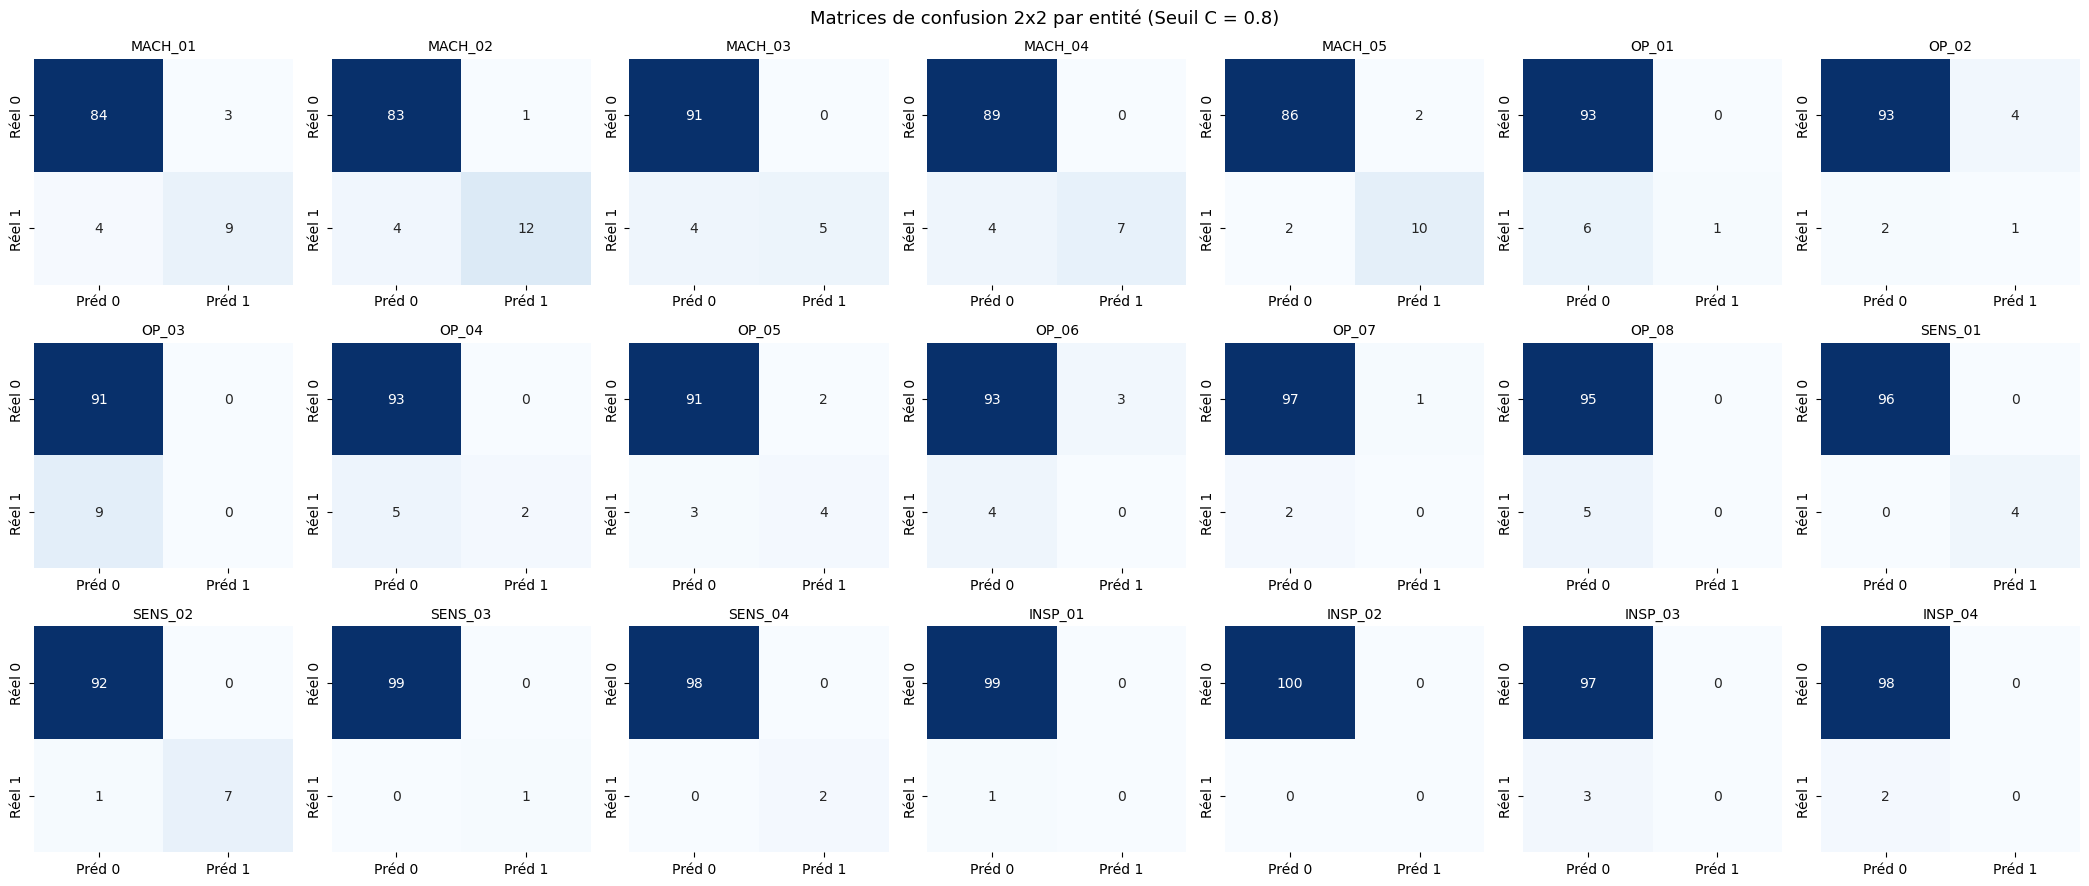

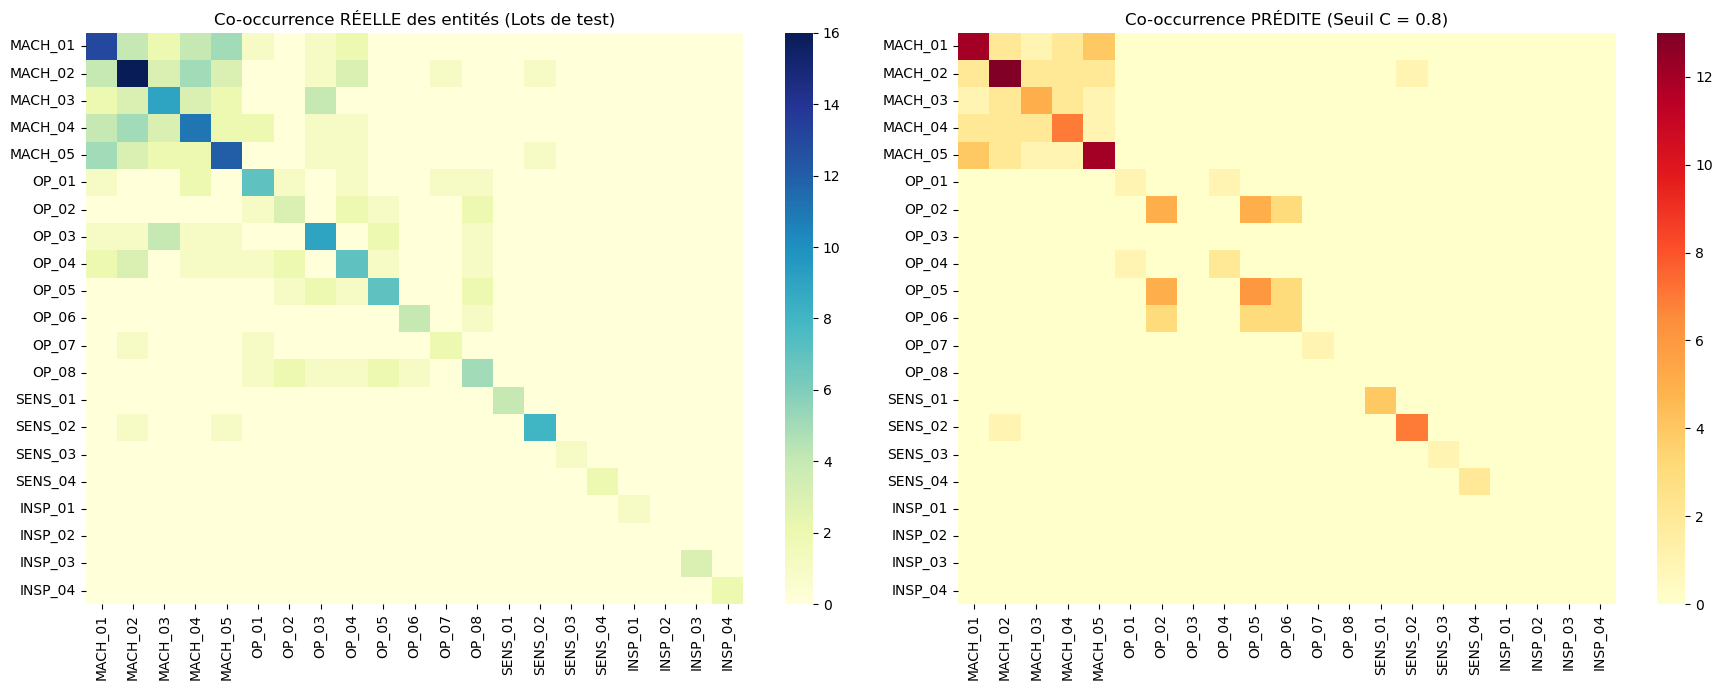

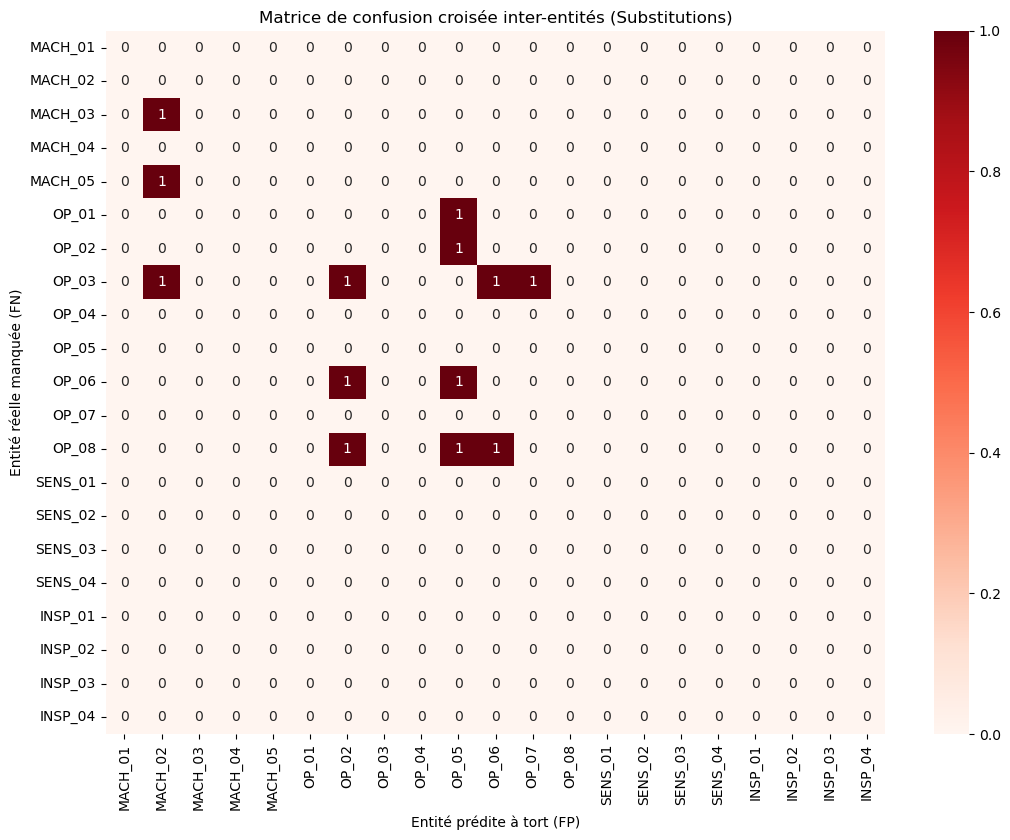

In [30]:
import seaborn as sns
from sklearn.metrics import multilabel_confusion_matrix

# Binarisation avec le seuil retenu (ex. EVAL_THRESHOLD)
y_true = y_test_mat.astype(int)
y_pred = (probs_test_df.values >= EVAL_THRESHOLD).astype(int)

# 1. Tableau TP / FP / FN / TN pour chacune des 21 entités
mcm = multilabel_confusion_matrix(y_true, y_pred)
cm_rows = []
for idx_e, ent in enumerate(ALL_ENTITIES):
    tn, fp, fn, tp = mcm[idx_e].ravel()
    cm_rows.append({
        "Entite": ent,
        "TP (Vrais Positifs)": int(tp),
        "FP (Fausses Alertes)": int(fp),
        "FN (Ratés)": int(fn),
        "TN (Vrais Négatifs)": int(tn),
    })

cm_summary_df = pd.DataFrame(cm_rows)
display(cm_summary_df)

# Grille visuelle des 21 matrices de confusion 2x2
fig, axes = plt.subplots(3, 7, figsize=(21, 9))
axes = axes.ravel()
for idx_e, ent in enumerate(ALL_ENTITIES):
    sns.heatmap(
        mcm[idx_e],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Préd 0", "Préd 1"],
        yticklabels=["Réel 0", "Réel 1"],
        ax=axes[idx_e],
    )
    axes[idx_e].set_title(ent, fontsize=10)
plt.suptitle(f"Matrices de confusion 2x2 par entité (Seuil C = {EVAL_THRESHOLD})", fontsize=13)
plt.tight_layout()
plt.show()

# 2. Matrices de co-occurrence : Réelle vs Prédite (21 x 21)
cooc_true = pd.DataFrame(y_true.T @ y_true, index=ALL_ENTITIES, columns=ALL_ENTITIES)
cooc_pred = pd.DataFrame(y_pred.T @ y_pred, index=ALL_ENTITIES, columns=ALL_ENTITIES)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(cooc_true, cmap="YlGnBu", ax=axes[0], cbar=True)
axes[0].set_title("Co-occurrence RÉELLE des entités (Lots de test)")

sns.heatmap(cooc_pred, cmap="YlOrRd", ax=axes[1], cbar=True)
axes[1].set_title(f"Co-occurrence PRÉDITE (Seuil C = {EVAL_THRESHOLD})")
plt.tight_layout()
plt.show()

# 3. Matrice de confusion croisée (quand une entité réelle est ratée, quelle entité est prédite ?)
fn_mask = (y_true == 1) & (y_pred == 0)
fp_mask = (y_true == 0) & (y_pred == 1)
cross_err = pd.DataFrame(fn_mask.T @ fp_mask, index=ALL_ENTITIES, columns=ALL_ENTITIES)

plt.figure(figsize=(11, 8.5))
sns.heatmap(cross_err, annot=True, fmt="d", cmap="Reds")
plt.xlabel("Entité prédite à tort (FP)")
plt.ylabel("Entité réelle manquée (FN)")
plt.title("Matrice de confusion croisée inter-entités (Substitutions)")
plt.tight_layout()
plt.show()

In [32]:
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

best_row = curve_df.loc[curve_df["F1_Micro"].idxmax()]

# Calculer le ROC-AUC colonne par colonne uniquement sur les classes ayant des 0 et des 1 dans y_test_mat
valid_aucs = []
for col_idx in range(y_test_mat.shape[1]):
    y_col = y_test_mat[:, col_idx]
    if len(np.unique(y_col)) == 2:
        valid_aucs.append(roc_auc_score(y_col, probs_test_df.values[:, col_idx]))

macro_auc_valid = float(np.mean(valid_aucs)) if valid_aucs else np.nan
micro_ap = float(average_precision_score(y_test_mat, probs_test_df.values, average="micro"))
macro_ap_valid = float(
    average_precision_score(
        y_test_mat[:, [i for i in range(y_test_mat.shape[1]) if len(np.unique(y_test_mat[:, i])) == 2]],
        probs_test_df.values[:, [i for i in range(y_test_mat.shape[1]) if len(np.unique(y_test_mat[:, i])) == 2]],
        average="macro",
    )
)

summary_model = pd.DataFrame([{
    "Seuil_Retenu": best_row["Seuil_C"],
    "F1_Micro": round(best_row["F1_Micro"], 4),
    "F1_Macro": round(best_row["F1_Macro"], 4),
    "Precision_Micro": round(best_row["Precision_Micro"], 4),
    "Recall_Micro": round(best_row["Recall_Micro"], 4),
    "Hamming_Loss": round(best_row["Hamming_Loss"], 4),
    "Exact_Match": round(best_row["Exact_Match"], 4),
    "Macro_ROC_AUC_Valides": round(macro_auc_valid, 4),
    "Micro_PR_AUC": round(micro_ap, 4),
    "Macro_PR_AUC_Valides": round(macro_ap_valid, 4),
    "Nb_Classes_Evaluees": f"{len(valid_aucs)}/{y_test_mat.shape[1]}",
}])

display(summary_model)

,Seuil_Retenu,F1_Micro,F1_Macro,Precision_Micro,Recall_Micro,Hamming_Loss,Exact_Match,Macro_ROC_AUC_Valides,Micro_PR_AUC,Macro_PR_AUC_Valides,Nb_Classes_Evaluees
0,0.8,0.628,0.446,0.8025,0.5159,0.0367,0.51,0.878,0.6732,0.5665,20/21
